Iteration: 1 Best Error: 1.1131
Iteration: 2 Best Error: 1.1131
Iteration: 3 Best Error: 1.1131
Iteration: 4 Best Error: 1.1131
Iteration: 5 Best Error: 1.1131
Iteration: 6 Best Error: 1.1131
Iteration: 7 Best Error: 1.1131
Iteration: 8 Best Error: 1.11302
Iteration: 9 Best Error: 1.11302
Iteration: 10 Best Error: 1.11302
Iteration: 11 Best Error: 1.11302
Iteration: 12 Best Error: 1.11302
Iteration: 13 Best Error: 1.11302
Iteration: 14 Best Error: 1.11302
Iteration: 15 Best Error: 1.11302
Iteration: 16 Best Error: 1.11302
Iteration: 17 Best Error: 1.11302
Iteration: 18 Best Error: 1.11302
Iteration: 19 Best Error: 1.11302
Iteration: 20 Best Error: 1.11302

Best Parameters:
C = 66.2771577689367
Gamma = 0.1193841209745534
Epsilon = 0.14515358451567367

Performance Results
RMSE: 3.0
MAE: 2.38
MAPE: 1.62 %


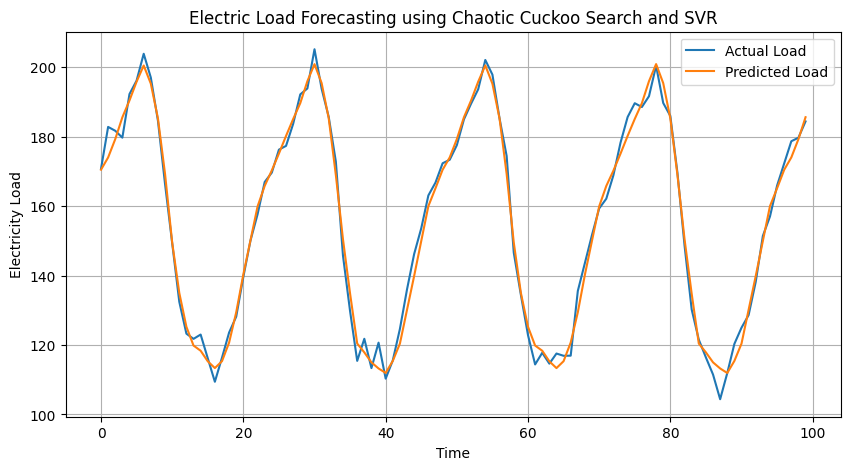

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# 1. Generate sample electricity load data
np.random.seed(42)

daily_pattern = np.array([
    120, 118, 115, 113, 112, 115, 120, 130,
    140, 150, 160, 165, 170, 175, 180, 185,
    190, 195, 200, 195, 185, 170, 150, 135,
    125, 120, 118, 115, 113, 115, 120, 130,
    140, 150, 160, 165, 170, 175, 180, 185,
    190, 195, 200, 195, 185, 170, 150, 135
])

load = np.tile(daily_pattern, 40)
load = load + np.random.normal(0, 3, len(load))

# 2. Seasonal adjustment
season_length = 48
train_size = int(len(load) * 0.6)

seasonal_factors = np.zeros(season_length)

for i in range(season_length):
    seasonal_factors[i] = np.mean(
        load[:train_size][np.arange(train_size) % season_length == i]
    )

seasonal_factors = seasonal_factors / np.mean(load[:train_size])

adjusted_load = np.array([
    load[i] / seasonal_factors[i % season_length]
    for i in range(len(load))
])

# 3. Create input and output data
lag = 48
X = []
y = []

for i in range(lag, len(adjusted_load)):
    X.append(adjusted_load[i-lag:i])
    y.append(adjusted_load[i])

X = np.array(X)
y = np.array(y)

# 4. Split data chronologically
n = len(X)

train_end = int(n * 0.5625)
val_end = int(n * 0.75)

X_train = X[:train_end]
y_train = y[:train_end]

X_val = X[train_end:val_end]
y_val = y[train_end:val_end]

X_test = X[val_end:]
y_test = y[val_end:]

# 5. Scale the data
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train)
X_val = x_scaler.transform(X_val)
X_test = x_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

y_val_scaled = y_scaler.transform(
    y_val.reshape(-1, 1)
).ravel()

# 6. Define SVR fitness function
def fitness(params):
    C, gamma, epsilon = params

    model = SVR(
        kernel='rbf',
        C=C,
        gamma=gamma,
        epsilon=epsilon
    )

    model.fit(X_train, y_train_scaled)
    prediction = model.predict(X_val)

    return mean_squared_error(y_val_scaled, prediction)

# 7. Initialize Cuckoo Search
n_nests = 12
iterations = 20
pa = 0.25

lower = np.array([0.1, 0.001, 0.001])
upper = np.array([100, 1, 0.5])

nests = np.random.uniform(
    lower, upper, (n_nests, 3)
)

best_nest = nests[0].copy()
best_score = float('inf')

# 8. Chaotic Tent Map
chaos = 0.35

def tent_map(x):
    if x < 0.5:
        return 2 * x
    else:
        return 2 * (1 - x)

# 9. Levy Flight
def levy_flight():
    beta = 1.5

    sigma = (
        math.gamma(1 + beta) * math.sin(math.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (abs(v) ** (1 / beta) + 1e-10)

# 10. Cuckoo Search Optimization
for iteration in range(iterations):

    scores = np.array([fitness(nest) for nest in nests])

    best_index = np.argmin(scores)

    if scores[best_index] < best_score:
        best_score = scores[best_index]
        best_nest = nests[best_index].copy()

    for i in range(n_nests):

        chaos = tent_map(chaos)

        new_nest = nests[i] + (
            0.01 * levy_flight() * chaos
            * (nests[i] - best_nest)
        )

        new_nest = np.clip(new_nest, lower, upper)

        new_score = fitness(new_nest)

        if new_score < scores[i]:
            nests[i] = new_nest

    # Abandon some nests and create new ones
    for i in range(n_nests):
        if random.random() < pa:
            nests[i] = np.random.uniform(lower, upper)

    print("Iteration:", iteration + 1,
          "Best Error:", round(best_score, 5))

# 11. Train final SVR model
C, gamma, epsilon = best_nest

print("\nBest Parameters:")
print("C =", C)
print("Gamma =", gamma)
print("Epsilon =", epsilon)

X_final = np.vstack((X_train, X_val))
y_final = np.concatenate((y_train_scaled, y_val_scaled))

model = SVR(
    kernel='rbf',
    C=C,
    gamma=gamma,
    epsilon=epsilon
)

model.fit(X_final, y_final)

# 12. Predict test data
prediction_scaled = model.predict(X_test)

prediction = y_scaler.inverse_transform(
    prediction_scaled.reshape(-1, 1)
).ravel()

actual = y_test

# Restore seasonal values
test_start = val_end + lag

for i in range(len(prediction)):
    factor = seasonal_factors[
        (test_start + i) % season_length
    ]

    prediction[i] *= factor

    actual[i] *= factor

# 13. Calculate performance
rmse = np.sqrt(mean_squared_error(actual, prediction))
mae = mean_absolute_error(actual, prediction)

mape = np.mean(
    np.abs((actual - prediction) / (actual + 1e-10))
) * 100

print("\nPerformance Results")
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("MAPE:", round(mape, 2), "%")

# 14. Plot actual vs predicted load
plt.figure(figsize=(10, 5))

plt.plot(actual[:100], label="Actual Load")
plt.plot(prediction[:100], label="Predicted Load")

plt.xlabel("Time")
plt.ylabel("Electricity Load")
plt.title("Electric Load Forecasting using Chaotic Cuckoo Search and SVR")

plt.legend()
plt.grid()
plt.show()
